# Workstream A: a model that sees the community and plans ahead

## Step 1: a model that sees the community

**Question.** Real gain falls when newcomers compete with their own community (δ < 0), even when the model is retrained every round. Is that because the model cannot see how large the community in a state already is?

**Set-up.** Three versions of the same gradient-boosting model, all trained only on observed outcomes:

| features | what the model sees besides the person and the state |
|---|---|
| `base` | nothing (the v2 model) |
| `community` | share of co-nationals among all foreigners in the state, C[state, origin] |
| `community_recent` | the same plus the share of last round's arrivals, R[state, origin] |

Grid: `configs/community_model.yaml` (54 points × 5 seeds). This notebook only reads `results/community_model/`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from refugee_sim.simulation import load_results

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

runs = load_results("../results/community_model")
print(f"{runs['run_key'].nunique()} runs loaded")

FEATURES = ["base", "community", "community_recent"]
FEATURE_LABEL = {"base": "does not see community", "community": "sees community",
                 "community_recent": "sees community + recent arrivals"}
FEATURE_COLOR = {"base": "#555555", "community": "#2F6FB5", "community_recent": "#E07B28"}
POLICY_STYLE = {"fixed": "--", "every_round": "-"}
SCENARIOS = ["SOEP", "none", "stylised x4"]
DELTAS = [-0.3, 0.0, 0.3]


def mean_by_round(df, column):
    return df.groupby("round")[column].mean()

270 runs loaded


## 1. Real gain over random quota placement

Rows: interaction scenario (SOEP is the main one). Columns: community effect δ. Solid = retrained every round, dashed = fixed model. Dotted = best possible gain (oracle).

Note: for the fixed model the two community versions coincide, because it is trained once on the historical data, where no recent arrivals exist yet (R = 0).

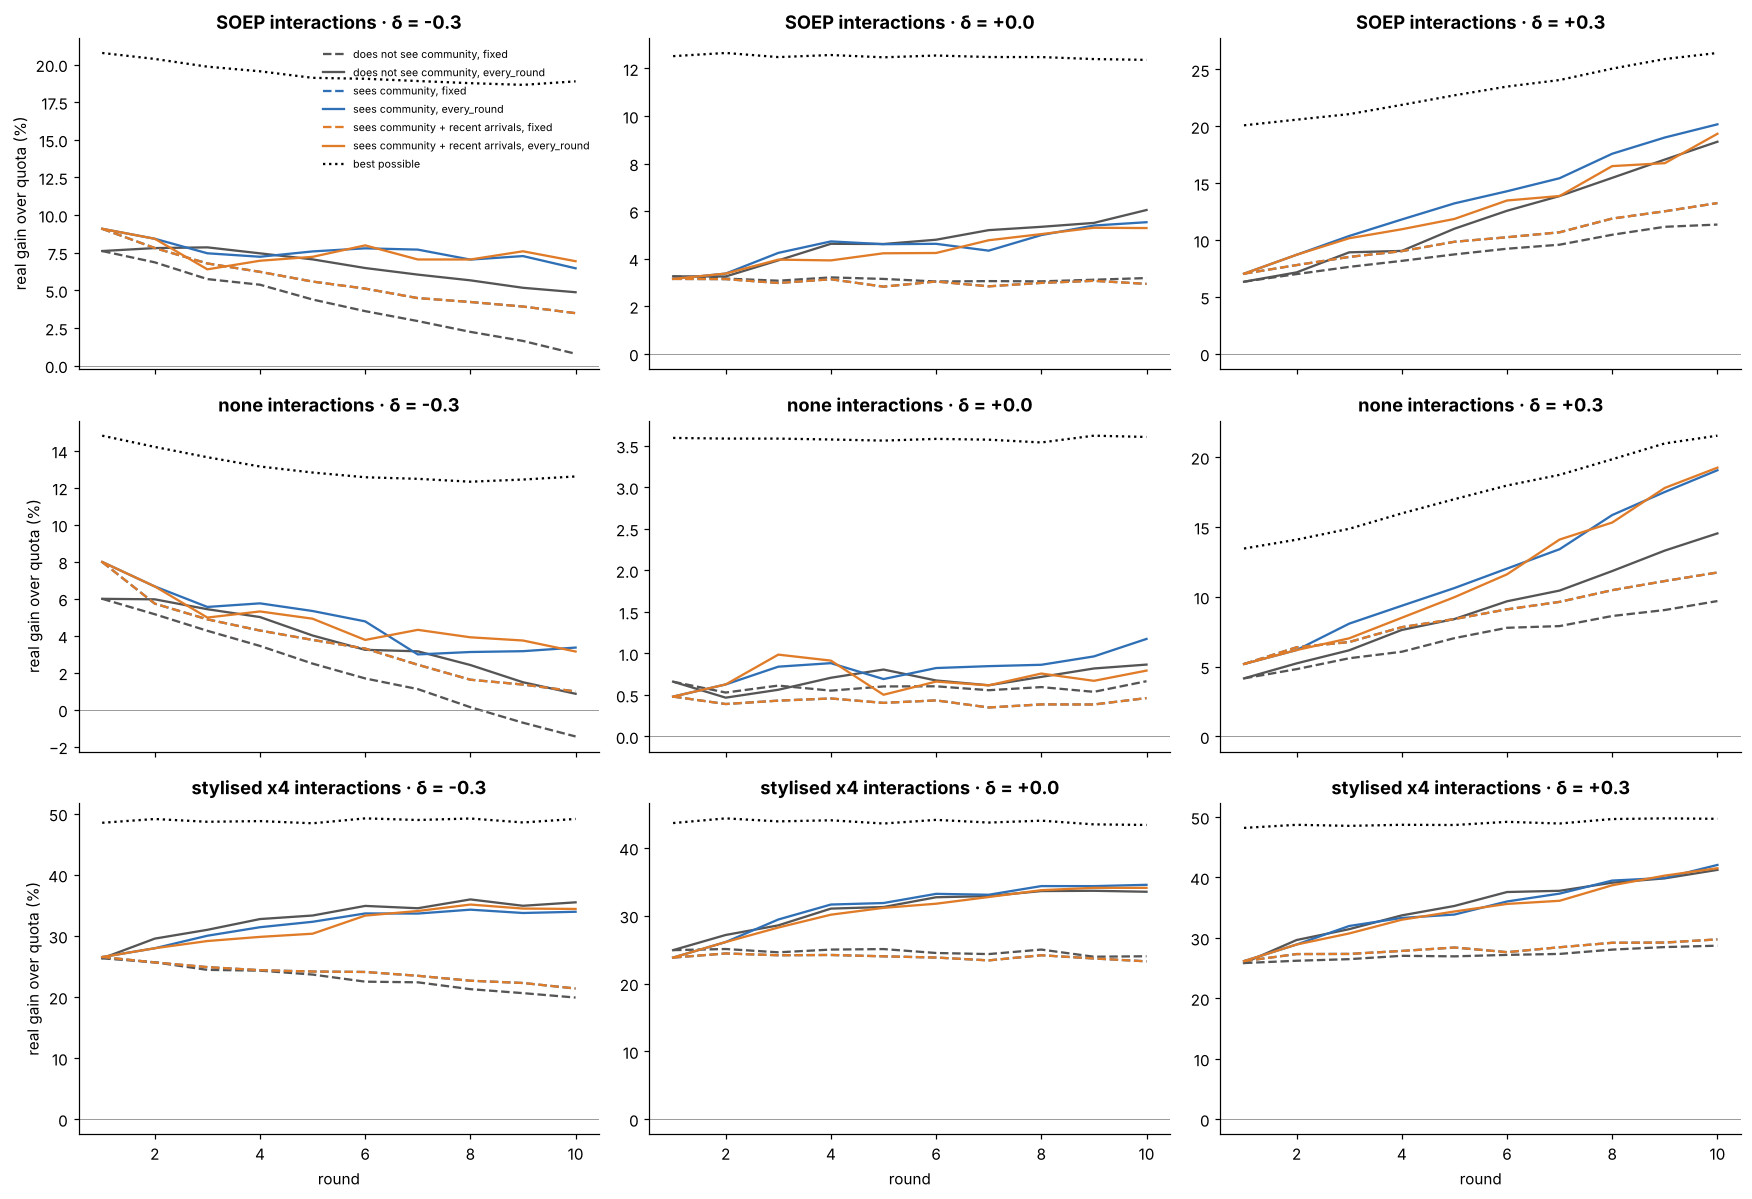

In [2]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11), sharex=True)
for i, s in enumerate(SCENARIOS):
    for j, d in enumerate(DELTAS):
        ax = axes[i, j]
        cell = runs[(runs["interactions"] == s) & (runs["delta"] == d)]
        for f in FEATURES:
            for p, ls in POLICY_STYLE.items():
                g = mean_by_round(cell[(cell["features"] == f) & (cell["policy"] == p)], "gain_pct")
                ax.plot(g.index, g, ls, color=FEATURE_COLOR[f], label=f"{FEATURE_LABEL[f]}, {p}")
        oracle = mean_by_round(cell[(cell["features"] == "base") & (cell["policy"] == "fixed")], "oracle_gain_pct")
        ax.plot(oracle.index, oracle, ":", color="k", label="best possible")
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_title(f"{s} interactions · δ = {d:+.1f}", fontweight="bold")
        if j == 0:
            ax.set_ylabel("real gain over quota (%)")
        if i == 2:
            ax.set_xlabel("round")
axes[0, 0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/ws_a_real_gain.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Round 1 vs round 10

`captured_pct` = share of the best possible gain the model achieves; `promised_gain_pct` = gain the model itself expects.

In [3]:
COLUMNS = ["gain_pct", "captured_pct", "promised_gain_pct"]
table = (runs[runs["round"].isin([1, 10])]
         .groupby(["interactions", "delta", "policy", "features", "round"])[COLUMNS].mean()
         .unstack("round").round(1))
table.loc[["SOEP"]]

gain_pct       captured_pct  \
round                                                 1     10           1    
interactions delta policy      features                                       
SOEP         -0.3  every_round base                  7.6   4.9         36.7   
                               community             9.1   6.5         43.8   
                               community_recent      9.1   6.9         43.8   
                   fixed       base                  7.6   0.8         36.7   
                               community             9.1   3.5         43.8   
                               community_recent      9.1   3.5         43.8   
              0.0  every_round base                  3.3   6.0         26.0   
                               community             3.1   5.5         25.2   
                               community_recent      3.1   5.3         25.2   
                   fixed       base                  3.3   3.2         26.0   
                               community             3.1   2.9         25.2   
                               community_recent      3.1   2.9         25.2   
              0.3  every_round base                  6.3  18.6         31.5   
                               community             7.0  20.2         35.0   
                               community_recent      7.0  19.3         35.0   
                   fixed       base                  6.3  11.4         31.5   
                               community             7.0  13.3         35.0   
                               community_recent      7.0  13.3         35.0   

                                                      promised_gain_pct        
round                                              10                1     10  
interactions delta policy      features                                        
SOEP         -0.3  every_round base              27.1              32.9  24.5  
                               community         39.8              37.1  14.9  
                               community_recent  41.8              37.1  15.3  
                   fixed       base               4.3              32.9  47.6  
                               community         20.3              37.1  32.0  
                               community_recent  20.3              37.1  32.0  
              0.0  every_round base              48.9              30.7  13.8  
                               community         44.7              31.2  12.3  
                               community_recent  42.8              31.2  13.1  
                   fixed       base              25.9              30.7  29.6  
                               community         23.8              31.2  27.6  
                               community_recent  23.8              31.2  27.6  
              0.3  every_round base              66.9              33.7   9.6  
                               community         67.1              35.3  18.2  
                               community_recent  67.0              35.3  16.1  
                   fixed       base              42.5              33.7  13.2  
                               community         48.8              35.3  17.3  
                               community_recent  48.8              35.3  17.3

In [4]:
table.loc[["none", "stylised x4"]]

gain_pct       captured_pct  \
round                                                 1     10           1    
interactions delta policy      features                                       
none         -0.3  every_round base                  6.0   0.9         40.5   
                               community             8.0   3.4         53.9   
                               community_recent      8.0   3.1         53.9   
                   fixed       base                  6.0  -1.4         40.5   
                               community             8.0   1.0         53.9   
                               community_recent      8.0   1.0         53.9   
              0.0  every_round base                  0.7   0.9         18.6   
                               community             0.5   1.2         13.5   
                               community_recent      0.5   0.8         13.5   
                   fixed       base                  0.7   0.7         18.6   
                               community             0.5   0.5         13.5   
                               community_recent      0.5   0.5         13.5   
              0.3  every_round base                  4.2  14.5         30.9   
                               community             5.2  19.1         38.5   
                               community_recent      5.2  19.2         38.5   
                   fixed       base                  4.2   9.7         30.9   
                               community             5.2  11.7         38.5   
                               community_recent      5.2  11.7         38.5   
stylised x4  -0.3  every_round base                 26.3  35.5         54.2   
                               community            26.5  33.9         54.7   
                               community_recent     26.5  34.4         54.7   
                   fixed       base                 26.3  19.9         54.2   
                               community            26.5  21.4         54.7   
                               community_recent     26.5  21.4         54.7   
              0.0  every_round base                 24.9  33.5         57.1   
                               community            23.8  34.6         54.6   
                               community_recent     23.8  34.1         54.6   
                   fixed       base                 24.9  24.0         57.1   
                               community            23.8  23.3         54.6   
                               community_recent     23.8  23.3         54.6   
              0.3  every_round base                 25.8  41.3         53.6   
                               community            26.2  42.1         54.3   
                               community_recent     26.2  41.5         54.3   
                   fixed       base                 25.8  28.7         53.6   
                               community            26.2  29.8         54.3   
                               community_recent     26.2  29.8         54.3   

                                                      promised_gain_pct        
round                                              10                1     10  
interactions delta policy      features                                        
none         -0.3  every_round base               8.4              31.4  22.5  
                               community         38.5              35.5  14.1  
                               community_recent  34.0              35.5  13.2  
                   fixed       base             -10.6              31.4  46.2  
                               community         10.2              35.5  30.1  
                               community_recent  10.2              35.5  30.1  
              0.0  every_round base              24.1              28.3   9.6  
                               community         32.7              30.0   9.7  
                               community_recent  22.1              30.0   9.7  
      

## 3. Does the model avoid crowded states?

Mean standardised community size z in the states where people were placed. Under competition (δ < 0) a model that understands the community should move people away from large communities, so its line should lie below the blind model's.

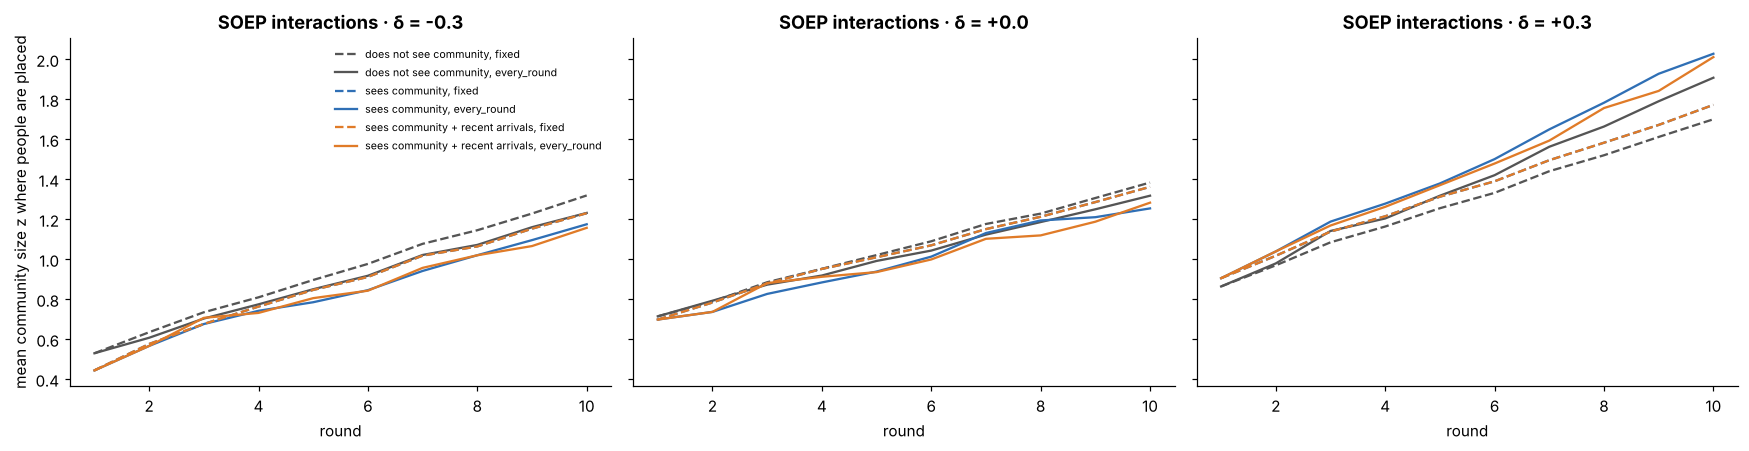

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
soep = runs[runs["interactions"] == "SOEP"]
for ax, d in zip(axes, DELTAS):
    for f in FEATURES:
        for p, ls in POLICY_STYLE.items():
            z = mean_by_round(soep[(soep["delta"] == d) & (soep["features"] == f) & (soep["policy"] == p)], "mean_z_placed")
            ax.plot(z.index, z, ls, color=FEATURE_COLOR[f], label=f"{FEATURE_LABEL[f]}, {p}")
    ax.set_title(f"SOEP interactions · δ = {d:+.1f}", fontweight="bold")
    ax.set_xlabel("round")
axes[0].set_ylabel("mean community size z where people are placed")
axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/ws_a_community_placed.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Promised vs real gain (SOEP, δ = −0.3)

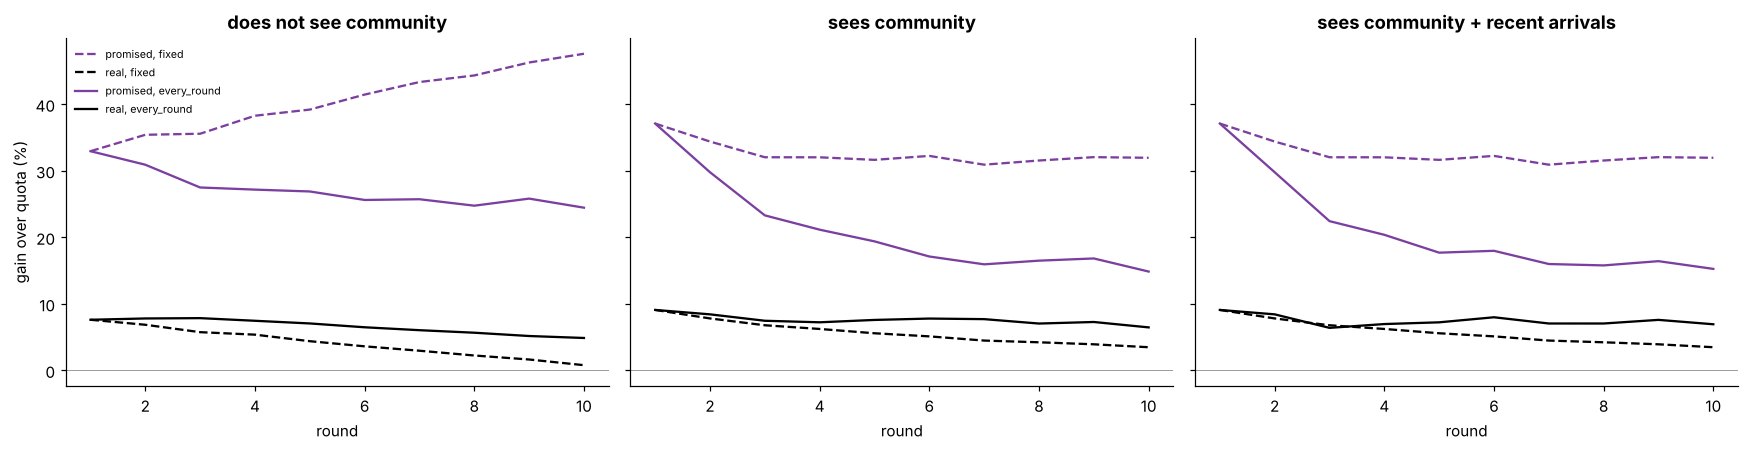

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
cell = soep[soep["delta"] == -0.3]
for ax, f in zip(axes, FEATURES):
    for p, ls in POLICY_STYLE.items():
        m = cell[(cell["features"] == f) & (cell["policy"] == p)].groupby("round")[["gain_pct", "promised_gain_pct"]].mean()
        ax.plot(m.index, m["promised_gain_pct"], ls, color="#7B3FA0", label=f"promised, {p}")
        ax.plot(m.index, m["gain_pct"], ls, color="k", label=f"real, {p}")
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"{FEATURE_LABEL[f]}", fontweight="bold")
    ax.set_xlabel("round")
axes[0].set_ylabel("gain over quota (%)")
axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/ws_a_promised_vs_real.png", dpi=150, bbox_inches="tight")
plt.show()

## What we learn (SOEP interactions, δ = −0.3, round 10, mean of 5 seeds)

- **Seeing the community helps, but does not stop the decline.** Fixed model: real gain +0.8% → +3.5%; retrained every round: +4.9% → +6.5%. Both still fall from +9.1% in round 1.
- **The model captures more of the best possible gain:** 27% → 40–42% when retrained, 4% → 20% when fixed.
- **It promises much less, but still too much.** Retrained: promised +15% vs real +6.5% (the blind model: +24.5% vs +4.9%). Fixed: +32% vs +3.5% (blind: +48% vs +0.8%).
- **Recent arrivals add nothing here**, as expected: in the linear ground truth only the total community matters.
- **With no community effect (δ = 0) nothing changes**, so the extra inputs do not hurt.
- **The best possible gain itself falls** (≈ 21% → 19%), because the oracle is also short-sighted: it places each cohort well but ignores what that does to the next one.

So the failure is partly missing information and partly short-sightedness. Next step (A3–A4): a forward-looking placement that accounts for how each placement changes the community, and a forward-looking oracle as its benchmark.

---
## Step 3: forward-looking placement

A greedy placement gives each person the best state for them now. Every placement also raises the co-national share in that state, which changes the chances of the next arrivals of that origin. The forward-looking placement (`policy.assign_forward`) adds this effect for `lookahead` future rounds. The slope of employment in community size is estimated from the model itself (or, for the oracle, from the truth).

Four placements are compared, all with the community-aware model retrained every round, SOEP interactions, 20 rounds (`configs/forward_looking.yaml`, 18 points × 5 seeds):

| | greedy (`lookahead` 0) | forward-looking (3 or 10 rounds) |
|---|---|---|
| learned model | as in step 1 | new |
| oracle (knows the truth) | the usual benchmark | new benchmark |

Real gain is measured, as before, against random quota placement in the same (changing) world.

90 runs loaded


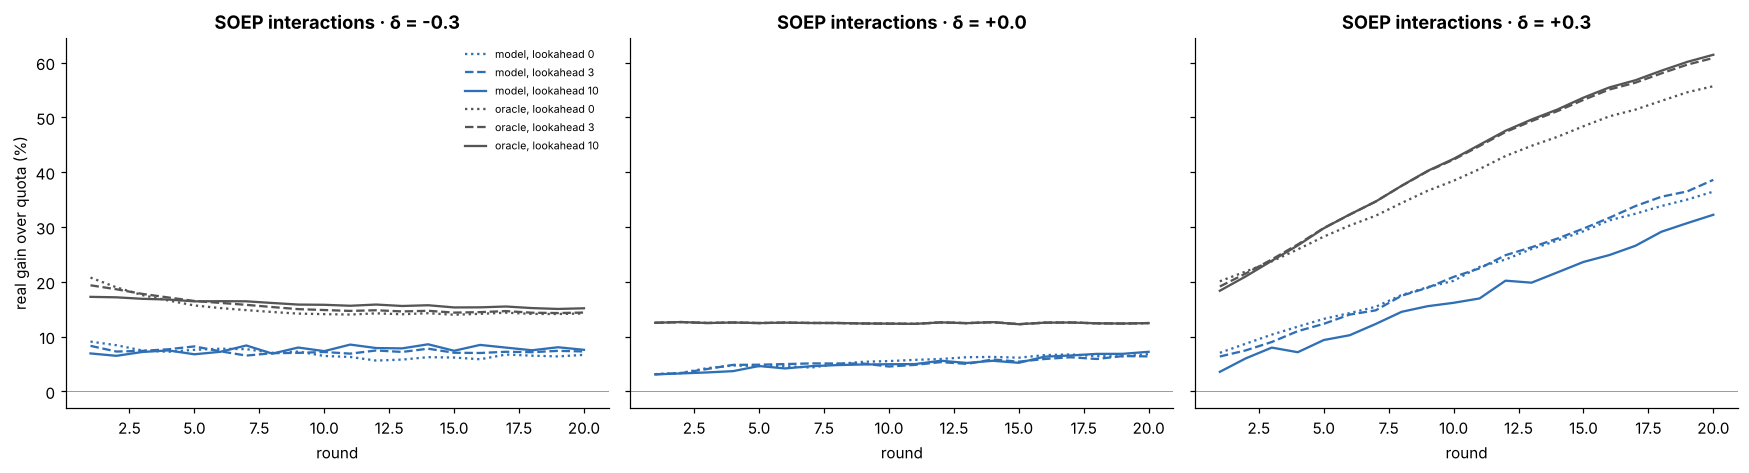

In [7]:
fw = load_results("../results/forward_looking")
print(f"{fw['run_key'].nunique()} runs loaded")
LOOKAHEAD_STYLE = {0: ":", 3: "--", 10: "-"}
PLANNER_COLOR = {"model": "#2F6FB5", "oracle": "#555555"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, d in zip(axes, DELTAS):
    for planner, color in PLANNER_COLOR.items():
        for la, ls in LOOKAHEAD_STYLE.items():
            g = mean_by_round(fw[(fw["delta"] == d) & (fw["planner"] == planner) & (fw["lookahead"] == la)], "gain_pct")
            ax.plot(g.index, g, ls, color=color, label=f"{planner}, lookahead {la}")
    ax.axhline(0, color="grey", lw=0.5)
    ax.set_title(f"SOEP interactions · δ = {d:+.1f}", fontweight="bold")
    ax.set_xlabel("round")
axes[0].set_ylabel("real gain over quota (%)")
axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/ws_a_forward_gain.png", dpi=150, bbox_inches="tight")
plt.show()

Total over the horizon: mean employment probability of everyone placed in rounds 1–20, and gain in the first and last five rounds.

In [8]:
def summarise(df):
    return pd.Series({
        "mean employment, rounds 1-20 (%)": 100 * df["welfare_algo"].mean(),
        "gain, rounds 1-5 (%)": df[df["round"] <= 5]["gain_pct"].mean(),
        "gain, rounds 16-20 (%)": df[df["round"] >= 16]["gain_pct"].mean(),
    })

totals = fw.groupby(["delta", "planner", "lookahead"]).apply(summarise).round(2)
totals

mean employment, rounds 1-20 (%)  \
delta planner lookahead                                     
-0.3  model   0                                     14.33   
              3                                     14.37   
              10                                    14.42   
      oracle  0                                     15.45   
              3                                     15.50   
              10                                    15.55   
 0.0  model   0                                     15.79   
              3                                     15.75   
              10                                    15.74   
      oracle  0                                     16.85   
              3                                     16.85   
              10                                    16.85   
 0.3  model   0                                     21.76   
              3                                     21.63   
              10                                    20.66   
      oracle  0                                     25.22   
              3                                     25.92   
              10                                    25.95   

                         gain, rounds 1-5 (%)  gain, rounds 16-20 (%)  
delta planner lookahead                                                
-0.3  model   0                          7.96                    6.43  
              3                          7.77                    7.22  
              10                         6.97                    7.92  
      oracle  0                         17.92                   14.20  
              3                         17.88                   14.43  
              10                        16.90                   15.25  
 0.0  model   0                          4.02                    6.60  
              3                          4.05                    6.18  
              10                         3.63                    6.76  
      oracle  0                         12.54                   12.48  
              3                         12.54                   12.48  
              10                        12.54                   12.48  
 0.3  model   0                         10.23                   33.78  
              3                          9.24                   35.22  
              10                         6.82                   28.70  
      oracle  0                         23.97                   52.98  
              3                         24.27                   57.98  
              10                        23.91                   58.46

### What we learn from step 3 (SOEP, 20 rounds, mean of 5 seeds)

- **Competition (δ = −0.3): planning ahead helps a little.** It gives up some gain early (rounds 1–5: model 8.0% → 7.0%) for more later (rounds 16–20: 6.4% → 7.9%). Over all 20 rounds mean employment rises only from 14.33% to 14.42%; for the oracle, 15.45% → 15.55%.
- **No community effect (δ = 0): planning changes nothing**, as it should.
- **Support (δ = +0.3): planning matters a lot for the oracle** (rounds 16–20: 53% → 58%), because concentrating co-nationals pays off later. For the learned model it **backfires** at lookahead 10 (21.8% → 20.7%): it extrapolates the community effect beyond the communities it has seen and over-concentrates.
- **The largest gap is between the model and the oracle (≈ 1.1 points of employment under competition), not between greedy and forward-looking (≈ 0.1).** In our setting the cost of short-sightedness is small; the cost of not knowing the true effects is large.
- Part of the decline is not the algorithm's doing: as arrivals accumulate, communities grow everywhere and, under δ < 0, everyone's chances fall, including under random quota placement.

Open points: the forward step assumes future cohorts are placed like the current one; the learned slope is noisy (tree model); a longer horizon (50+ rounds) would show whether the small gain under competition grows.

---
## Step 5: can the community effect be learned from the algorithm's own data?

After each round an analyst fits a logit on all observed placements so far: employed ~ characteristics + state + origin + z (`refugee_sim.estimation`). The coefficient of z estimates δ. Control: the same with random quota placement (`policy.planner: random`). `configs/learning_delta.yaml`, 20 points × 5 seeds.

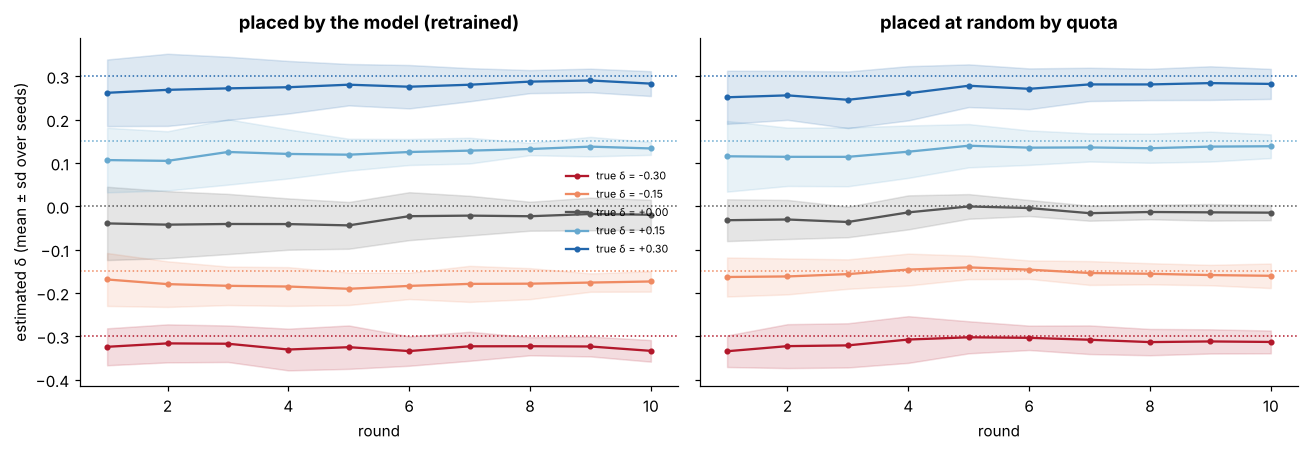

In [9]:
ld = load_results("../results/learning_delta")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, planner in zip(axes, ["model", "random"]):
    sub = ld[(ld["planner"] == planner) & (ld["policy"] == "every_round")]
    for d, c in zip([-0.3, -0.15, 0.0, 0.15, 0.3], ["#B2182B", "#EF8A62", "#555555", "#67A9CF", "#2166AC"]):
        g = sub[sub["delta"] == d].groupby("round")["delta_hat"].agg(["mean", "std"])
        ax.plot(g.index, g["mean"], "o-", ms=3, color=c, label=f"true δ = {d:+.2f}")
        ax.fill_between(g.index, g["mean"] - g["std"], g["mean"] + g["std"], color=c, alpha=0.15)
        ax.axhline(d, color=c, ls=":", lw=1)
    ax.set_title("placed by the model (retrained)" if planner == "model" else "placed at random by quota", fontweight="bold")
    ax.set_xlabel("round")
axes[0].set_ylabel("estimated δ (mean ± sd over seeds)")
axes[0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/ws_a_learning_delta.png", dpi=150, bbox_inches="tight")
plt.show()

### What we learn from step 5

- **δ is learned well.** By round 10 the estimate is within about 0.03 of the truth for every δ, with a spread of 0.02–0.05 across seeds.
- **The algorithm's own data are almost as good as random placement.** A slight extra pull away from zero under competition (−0.33 for a true −0.30), no sign of serious selection bias: placements depend only on observed characteristics.
- **So the model–oracle gap of step 3 is not about the community effect.** It comes from learning the person × state effects, which are small and noisy (consistent with the history experiment: more data, more of the oracle's gain).
- **Idea for the next step:** a hybrid model with an explicit linear z term (as here) can extrapolate to communities never seen, unlike the tree model. That may stop the forward-looking placement from backfiring under δ = +0.3.

---
## Step 6: which model class?

Three models, each greedy or forward-looking (lookahead 10), retrained every round, SOEP, 20 rounds (`configs/model_class.yaml`, 18 points × 3 seeds):

- `gbm`: gradient boosting that sees the community (steps 1–3);
- `hybrid`: boosting without community inputs + an explicit linear term δ̂·z (δ̂ from step 5), which extrapolates;
- `lasso`: L1 logit with characteristic × state interactions and z, as in Ahani et al. (2021).

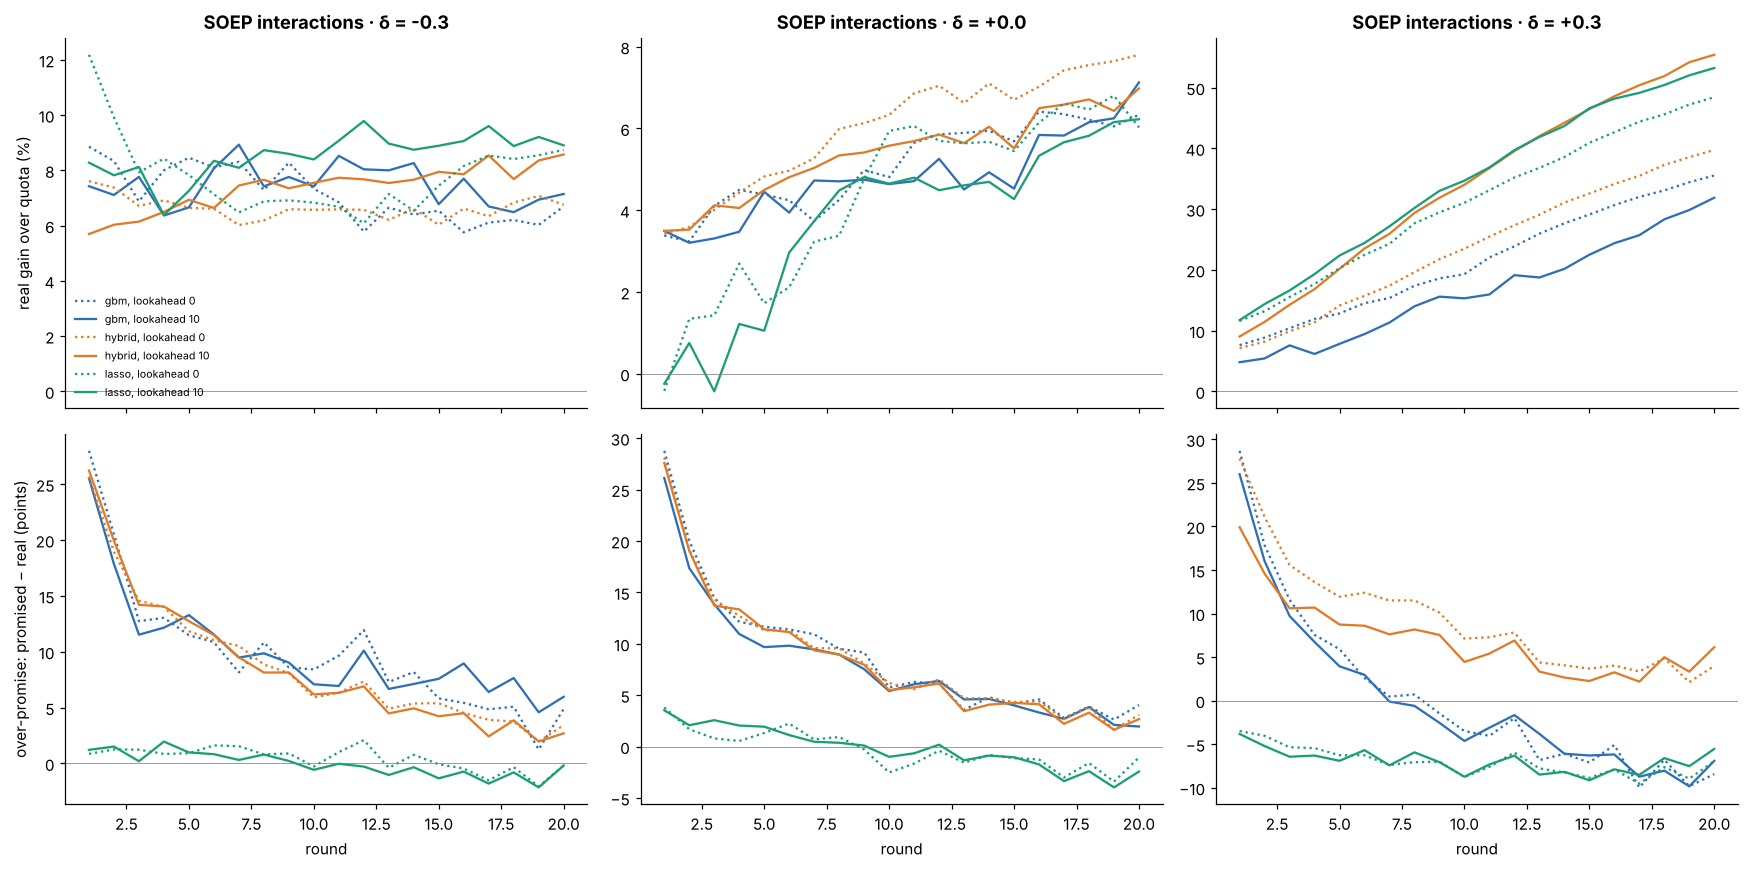

In [10]:
mc = load_results("../results/model_class")
MODEL_COLOR = {"gbm": "#2F6FB5", "hybrid": "#E07B28", "lasso": "#1B9E77"}
fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=True)
for j, d in enumerate(DELTAS):
    for m, c in MODEL_COLOR.items():
        for la, ls in ((0, ":"), (10, "-")):
            sub = mc[(mc["delta"] == d) & (mc["model"] == m) & (mc["lookahead"] == la)]
            g = sub.groupby("round")[["gain_pct", "promised_gain_pct"]].mean()
            axes[0, j].plot(g.index, g["gain_pct"], ls, color=c, label=f"{m}, lookahead {la}")
            axes[1, j].plot(g.index, g["promised_gain_pct"] - g["gain_pct"], ls, color=c)
    axes[0, j].set_title(f"SOEP interactions · δ = {d:+.1f}", fontweight="bold")
    axes[1, j].set_xlabel("round")
    for i in (0, 1):
        axes[i, j].axhline(0, color="grey", lw=0.5)
axes[0, 0].set_ylabel("real gain over quota (%)")
axes[1, 0].set_ylabel("over-promise: promised − real (points)")
axes[0, 0].legend(fontsize=7, frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/ws_a_model_class.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
(mc.groupby(["delta", "model", "lookahead"])
   .apply(lambda df: pd.Series({"mean employment (%)": 100 * df["welfare_algo"].mean(),
                                "gain, rounds 16-20 (%)": df[df["round"] >= 16]["gain_pct"].mean(),
                                "over-promise, rounds 16-20": (df["promised_gain_pct"] - df["gain_pct"])[df["round"] >= 16].mean()}))
   .round(2))

mean employment (%)  gain, rounds 16-20 (%)  \
delta model  lookahead                                                
-0.3  gbm    0                        14.35                    6.16   
             10                       14.40                    6.99   
      hybrid 0                        14.28                    6.73   
             10                       14.38                    8.20   
      lasso  0                        14.44                    8.48   
             10                       14.54                    9.13   
 0.0  gbm    0                        15.74                    6.27   
             10                       15.70                    6.24   
      hybrid 0                        15.88                    7.49   
             10                       15.79                    6.64   
      lasso  0                        15.63                    6.41   
             10                       15.54                    5.84   
 0.3  gbm    0                        21.76                   33.14   
             10                       20.55                   28.03   
      hybrid 0                        22.33                   37.04   
             10                       24.33                   52.09   
      lasso  0                        23.93                   45.66   
             10                       24.65                   50.60   

                        over-promise, rounds 16-20  
delta model  lookahead                              
-0.3  gbm    0                                4.30  
             10                               6.71  
      hybrid 0                                3.51  
             10                               3.09  
      lasso  0                               -0.91  
             10                              -1.13  
 0.0  gbm    0                                3.59  
             10                               2.78  
      hybrid 0                                3.13  
             10                               2.78  
      lasso  0                               -2.06  
             10                              -2.78  
 0.3  gbm    0                               -8.02  
             10                              -7.94  
      hybrid 0                                3.67  
             10                               3.98  
      lasso  0                               -8.19  
             10                              -7.22

### What we learn from step 6 (3 seeds, so differences below ~0.1 point are noise)

- **The hybrid fixes the backfire of planning ahead under support (δ = +0.3).** Mean employment over 20 rounds: greedy 22.3% → forward-looking 24.3%, close to the forward-looking oracle (26.0%). The tree model got worse with planning (21.8% → 20.6%).
- **The L1 logit is the best learned model under competition and support** (δ = −0.3: 14.5% vs oracle 15.6%; δ = +0.3: 24.7%) and **does not over-promise** (promised − real ≈ −1 to −8 points, i.e. it under-promises), while boosting over-promises by 3–7 points under δ ≤ 0. This matches Bastani et al.: simpler models suffer less from the winner's curse.
- **With no community effect** all three are within 0.3 points; the logit is slightly worse there.
- **Overall for workstream A:** the degradation is driven by how the model learns, not by short-sightedness. A model with an explicit, extrapolating community term (hybrid or logit) plus forward-looking placement gets most of the way to the oracle.

---
## Step 7: other shapes of the community effect

The best placements from steps 3–6 under five shapes (`configs/shapes.yaml`, 30 points × 3 seeds, 20 rounds, SOEP). Hybrid and L1 logit assume a linear effect, so the non-linear shapes also test what happens when that assumption is wrong. Measure: mean employment over 20 rounds and the share of the forward-looking oracle's level reached above random quota placement.

In [12]:
sh = load_results("../results/shapes").copy()
sh["shape"] = sh["form"] + " " + sh[["delta", "kappa", "delta_female", "delta_recent"]].astype(str).agg("/".join, axis=1)
sh["placement"] = sh["model"].where(sh["planner"] == "model", "oracle") + ", lookahead " + sh["lookahead"].astype(str)
mean_emp = sh.groupby(["shape", "placement"])["welfare_algo"].mean().mul(100).unstack()
random_emp = sh.groupby("shape")["welfare_random"].mean().mul(100)
best = mean_emp["oracle, lookahead 10"]
share = mean_emp.sub(random_emp, axis=0).div(best - random_emp, axis=0).mul(100)
order = ["gbm, lookahead 0", "lasso, lookahead 0", "lasso, lookahead 10", "hybrid, lookahead 10", "oracle, lookahead 0", "oracle, lookahead 10"]
print("mean employment over 20 rounds (%)")
display(mean_emp[order].round(2))
print("share of the forward-looking oracle's gain over random placement (%)")
share[order].round(0)

mean employment over 20 rounds (%)


placement,"gbm, lookahead 0","lasso, lookahead 0","lasso, lookahead 10","hybrid, lookahead 10","oracle, lookahead 0","oracle, lookahead 10"
shape,,,,,,
inverted_u 0.3/0.15/0.0/0.0,15.99,15.33,15.33,15.46,17.03,16.97
saturating -0.3/0.0/0.0/0.0,15.19,15.07,15.04,15.23,16.28,16.27
saturating 0.3/0.0/0.0/0.0,16.67,16.17,16.29,16.73,18.06,18.10
stock_vs_recent 0.15/0.0/0.0/-0.3,17.27,18.08,18.17,18.09,19.28,19.30
women_stronger 0.15/0.0/0.15/0.0,19.00,19.78,20.09,20.22,21.80,22.30


share of the forward-looking oracle's gain over random placement (%)


placement,"gbm, lookahead 0","lasso, lookahead 0","lasso, lookahead 10","hybrid, lookahead 10","oracle, lookahead 0","oracle, lookahead 10"
shape,,,,,,
inverted_u 0.3/0.15/0.0/0.0,65.0,42.0,42.0,47.0,102.0,100.0
saturating -0.3/0.0/0.0/0.0,41.0,34.0,32.0,43.0,100.0,100.0
saturating 0.3/0.0/0.0/0.0,48.0,29.0,34.0,50.0,99.0,100.0
stock_vs_recent 0.15/0.0/0.0/-0.3,40.0,64.0,67.0,64.0,99.0,100.0
women_stronger 0.15/0.0/0.15/0.0,41.0,55.0,61.0,63.0,91.0,100.0


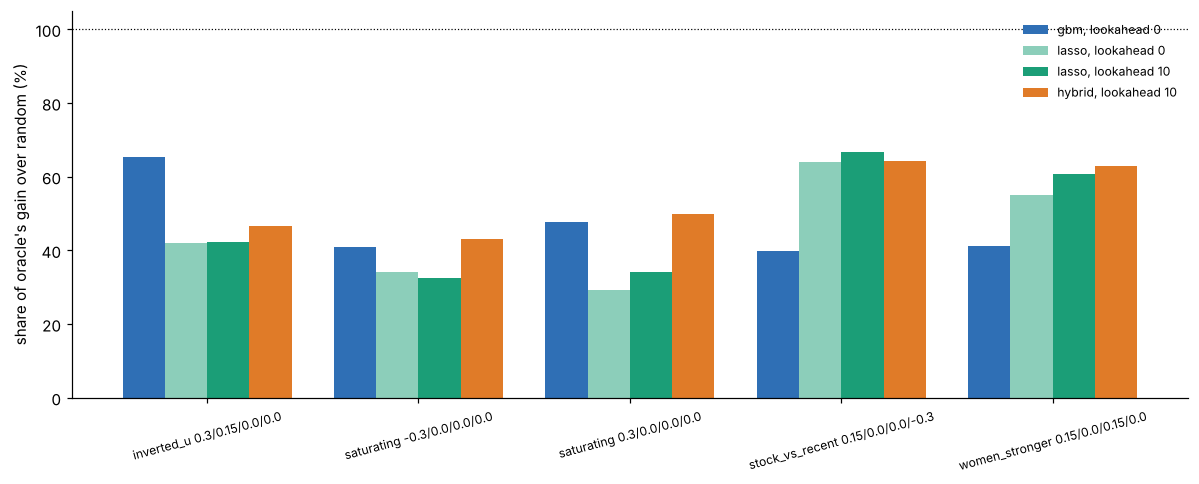

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.5))
x = np.arange(len(share))
for i, (col, c) in enumerate(zip(order[:4], ["#2F6FB5", "#1B9E77", "#1B9E77", "#E07B28"])):
    ax.bar(x + (i - 1.5) * 0.2, share[col], 0.2, color=c, alpha=0.5 if col == "lasso, lookahead 0" else 1, label=col)
ax.axhline(100, color="k", lw=0.8, ls=":")
ax.set_xticks(x, share.index, rotation=15, fontsize=8)
ax.set_ylabel("share of oracle's gain over random (%)")
ax.legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig("../results/figures/ws_a_shapes.png", dpi=150, bbox_inches="tight")
plt.show()

### What we learn from step 7 (3 seeds)

- **When the effect is close to linear, the explicit community term wins.** Established vs new arrivals and stronger-for-women: logit and hybrid reach 55–67% of the oracle's gain, boosting 40–41%.
- **When it is clearly non-linear, the linear term misleads.** Inverted U: boosting 65%, logit 42%, hybrid 47%. Saturating effects: boosting and hybrid are similar (41–50%), logit lowest (29–34%).
- **Planning ahead changes little for the learned models** (±0–6 points) and for the oracle (0–2 points), except stronger-for-women, where the oracle gains 9 points.
- **Overall for workstream A:** the main lever is how well the model learns the community effect; planning ahead adds little. A next model should keep the community term explicit but flexible (for example, a spline in z in the hybrid), so that it extrapolates without assuming a straight line.